## Cài đặt dữ liệu
Thực hiện cài đặt dữ liệu từ Kaggle

In [1]:
# Load packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso

from sklearn.neighbors import KNeighborsClassifier

from sklearn.decomposition import PCA

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.cluster import KMeans
from sklearn.svm import LinearSVC

from sklearn.pipeline import make_pipeline

from sklearn import metrics
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    mean_absolute_percentage_error,
    confusion_matrix,
    make_scorer,
    precision_score,
    recall_score,
    RocCurveDisplay,
    roc_auc_score,
    r2_score, f1_score
)


In [2]:
df_all = pd.read_csv('D:/Project/SmartCampus/Document/hospital_readmissions.csv')
df_all['age'] = df_all['age'].str.replace('[','(',regex=False)
df_all.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   age                25000 non-null  object
 1   time_in_hospital   25000 non-null  int64 
 2   n_lab_procedures   25000 non-null  int64 
 3   n_procedures       25000 non-null  int64 
 4   n_medications      25000 non-null  int64 
 5   n_outpatient       25000 non-null  int64 
 6   n_inpatient        25000 non-null  int64 
 7   n_emergency        25000 non-null  int64 
 8   medical_specialty  25000 non-null  object
 9   diag_1             25000 non-null  object
 10  diag_2             25000 non-null  object
 11  diag_3             25000 non-null  object
 12  glucose_test       25000 non-null  object
 13  A1Ctest            25000 non-null  object
 14  change             25000 non-null  object
 15  diabetes_med       25000 non-null  object
 16  readmitted         25000 non-null  objec

## Khai phá dữ liệu

In [3]:
df_all.shape
df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   age                25000 non-null  object
 1   time_in_hospital   25000 non-null  int64 
 2   n_lab_procedures   25000 non-null  int64 
 3   n_procedures       25000 non-null  int64 
 4   n_medications      25000 non-null  int64 
 5   n_outpatient       25000 non-null  int64 
 6   n_inpatient        25000 non-null  int64 
 7   n_emergency        25000 non-null  int64 
 8   medical_specialty  25000 non-null  object
 9   diag_1             25000 non-null  object
 10  diag_2             25000 non-null  object
 11  diag_3             25000 non-null  object
 12  glucose_test       25000 non-null  object
 13  A1Ctest            25000 non-null  object
 14  change             25000 non-null  object
 15  diabetes_med       25000 non-null  object
 16  readmitted         25000 non-null  objec

In [4]:
df_all.isnull().sum()

age                  0
time_in_hospital     0
n_lab_procedures     0
n_procedures         0
n_medications        0
n_outpatient         0
n_inpatient          0
n_emergency          0
medical_specialty    0
diag_1               0
diag_2               0
diag_3               0
glucose_test         0
A1Ctest              0
change               0
diabetes_med         0
readmitted           0
dtype: int64

In [5]:
cols = ['medical_specialty','diag_1','diag_2','diag_3']
for i in cols:
    print(i)
    print(df_all[i].unique())

medical_specialty
['Missing' 'Other' 'InternalMedicine' 'Family/GeneralPractice'
 'Cardiology' 'Surgery' 'Emergency/Trauma']
diag_1
['Circulatory' 'Other' 'Injury' 'Digestive' 'Respiratory' 'Diabetes'
 'Musculoskeletal' 'Missing']
diag_2
['Respiratory' 'Other' 'Circulatory' 'Injury' 'Diabetes' 'Digestive'
 'Musculoskeletal' 'Missing']
diag_3
['Other' 'Circulatory' 'Diabetes' 'Respiratory' 'Injury' 'Musculoskeletal'
 'Digestive' 'Missing']


In [6]:
df_all['diag_1'] = np.where(df_all['diag_1'] == 'Other', 
                            np.where(df_all['diag_2'] == 'Other',
                                     df_all['diag_3'],
                                     df_all['diag_2']
                                    ), 
                            df_all['diag_1'])
df_all['diag_1'].value_counts(normalize=True)

diag_1
Circulatory        0.39128
Respiratory        0.17760
Diabetes           0.12628
Digestive          0.10988
Injury             0.07576
Other              0.06272
Musculoskeletal    0.05600
Missing            0.00048
Name: proportion, dtype: float64

## Chuyển đổi dữ liệu

In [7]:
textCols = ['glucose_test','A1Ctest','change','diabetes_med','readmitted']
for i in textCols:
    print(i)
    print(df_all[i].unique())

glucose_test
['no' 'normal' 'high']
A1Ctest
['no' 'normal' 'high']
change
['no' 'yes']
diabetes_med
['yes' 'no']
readmitted
['no' 'yes']


In [8]:
binaryCols = ['change','diabetes_med','readmitted']
for i in binaryCols:
    df_all[i] = df_all[i].apply(lambda x: 0 if x == 'no' else 1)

In [9]:
noNormalHighCols = ['glucose_test','A1Ctest']
le = LabelEncoder()
for i in noNormalHighCols:
    #df_all[i] = le.fit_transform(df_all[i])
    df_all[i+'_ind'] = df_all[i].apply(lambda x: 0 if x == 'no' else 1 if x == 'normal' else 2)

df_all['age_t'] = le.fit_transform(df_all['age'])

In [10]:
df_all

,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted,glucose_test_ind,A1Ctest_ind,age_t
0,(70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,0,1,0,0,0,3
1,(70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,0,1,0,0,0,3
2,(50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,1,1,1,0,0,1
3,(70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,1,1,1,0,0,3
4,(60-70),1,42,0,7,0,0,0,InternalMedicine,Circulatory,Circulatory,Respiratory,no,no,0,1,0,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,(80-90),14,77,1,30,0,0,0,Missing,Circulatory,Other,Circulatory,no,normal,0,0,1,0,1,4
24996,(80-90),2,66,0,24,0,0,0,Missing,Digestive,Injury,Other,no,high,1,1,1,0,2,4
24997,(70-80),5,12,0,6,0,1,0,Missing,Other,Other,Other,normal,no,0,0,1,1,0,3
24998,(70-80),2,61,3,15,0,0,0,Family/GeneralPractice,Respiratory,Diabetes,Other,no,no,1,1,0,0,0,3


In [11]:
df_all.dtypes

age                  object
time_in_hospital      int64
n_lab_procedures      int64
n_procedures          int64
n_medications         int64
n_outpatient          int64
n_inpatient           int64
n_emergency           int64
medical_specialty    object
diag_1               object
diag_2               object
diag_3               object
glucose_test         object
A1Ctest              object
change                int64
diabetes_med          int64
readmitted            int64
glucose_test_ind      int64
A1Ctest_ind           int64
age_t                 int64
dtype: object

In [12]:
#Add diabetes indicator (i.e. if any of diagnoses are diabetes 1, else 0)
diagCols = ['diag_1','diag_2','diag_3']
diag = 'Diabetes'

df_all['Diabetes_ind'] = (df_all['diag_1'].str.contains(diag) | df_all['diag_2'].str.contains(diag) | df_all['diag_3'].str.contains(diag)) * 1


In [13]:
df_all[df_all['Diabetes_ind'] == 1].head()

,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,...,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted,glucose_test_ind,A1Ctest_ind,age_t,Diabetes_ind
3,(70-80),2,36,0,12,1,0,0,Missing,Circulatory,...,Diabetes,no,no,1,1,1,0,0,3,1
12,(70-80),8,67,0,21,0,0,0,Other,Diabetes,...,Other,no,normal,0,1,0,0,1,3,1
14,(80-90),2,73,1,26,0,0,0,InternalMedicine,Circulatory,...,Diabetes,no,no,0,1,0,0,0,4,1
16,(70-80),3,52,0,10,0,0,0,Other,Circulatory,...,Diabetes,no,no,0,1,1,0,0,3,1
18,(40-50),7,72,0,13,0,0,0,InternalMedicine,Diabetes,...,Other,no,high,0,1,1,0,2,0,1


In [14]:
df_all['readmitted'].value_counts(normalize=True)

readmitted
0    0.52984
1    0.47016
Name: proportion, dtype: float64

In [15]:
df_all[['Diabetes_ind','readmitted']].value_counts(normalize=True)

Diabetes_ind  readmitted
0             0             0.34188
              1             0.30660
1             0             0.18796
              1             0.16356
Name: proportion, dtype: float64

In [16]:
#Binning
visits = pd.qcut(df_all['n_lab_procedures'],[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
                      labels=['1st Decile', '2nd Decile','3rd Decile','4th Decile',
                              '5th Decile','6th Decile','7th Decile','8th Decile',
                              '9th Decile','10th Decile'])
df_all['n_lab_procedures_bucket'] = visits

# CHi thuốc thành 5 nhóm
medications = pd.qcut(df_all['n_medications'],[0, 0.2, 0.4, 0.6, 0.8, 1.0],
                      labels=['Low', 'Low Moderate','Moderate', 
                              'High', 'Very High'])
df_all['n_medications_bucket'] = medications

#n_outpatient bucketing
visits = pd.cut(df_all['n_outpatient'],bins = [-0.001, 0, 1, 10, 25],
                      labels=['None', 'One','Up to 10', 
                              'Up to 25'])
df_all['n_outpatient_bucket'] = visits

#n_emergency bucketing
visits = pd.cut(df_all['n_emergency'],bins = [-0.001, 0, 1, 10, 100],
                      labels=['None', 'One','Up to 10', 
                              '>10'])
df_all['n_emergency_bucket'] = visits

#n_inpatient bucketing
visits = pd.cut(df_all['n_inpatient'],bins = [-0.001, 0, 1, 5, 10, 15],
                      labels=['None', 'One','Up to 5','Up to 10', 
                              '>10'])
df_all['n_inpatient_bucket'] = visits


C:\Users\skyge\AppData\Local\Temp\ipykernel_21800\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


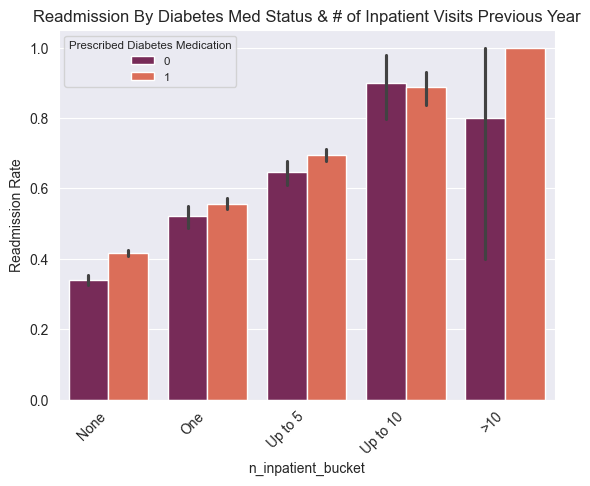

C:\Users\skyge\AppData\Local\Temp\ipykernel_21800\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


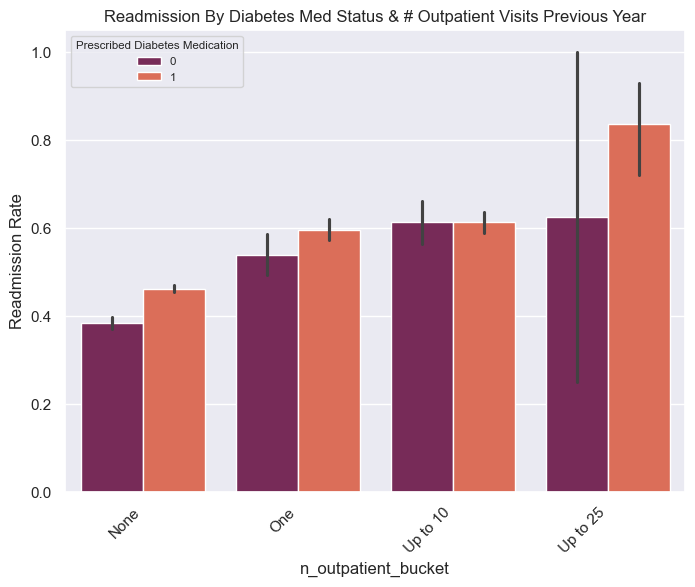

C:\Users\skyge\AppData\Local\Temp\ipykernel_21800\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


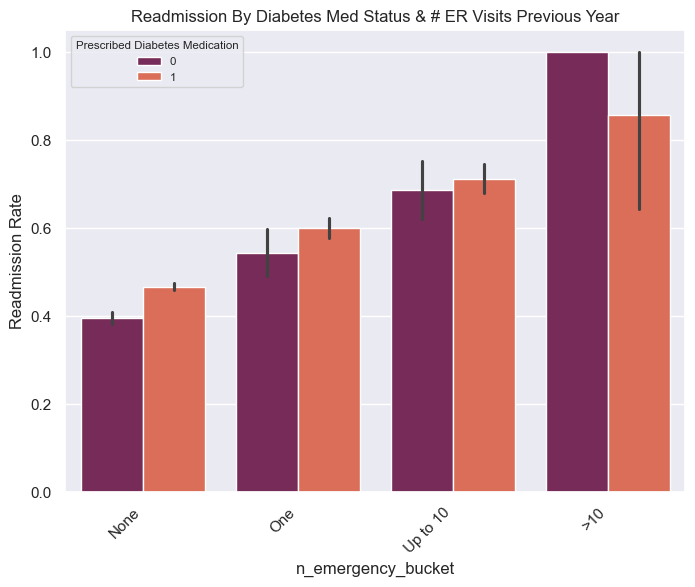

C:\Users\skyge\AppData\Local\Temp\ipykernel_21800\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


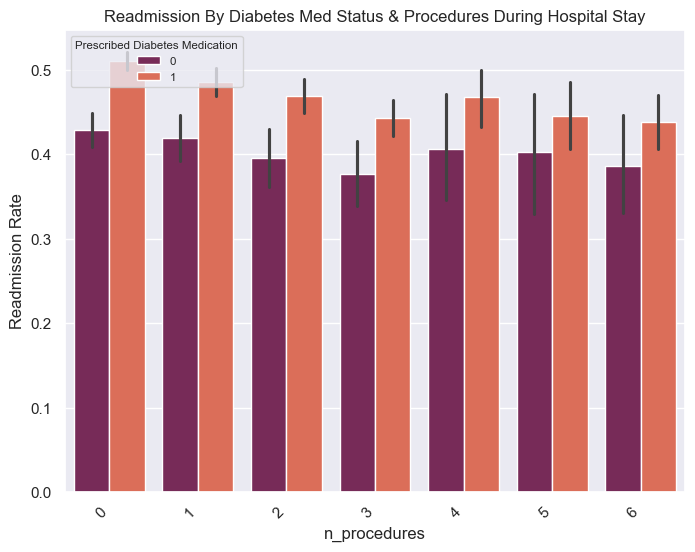

C:\Users\skyge\AppData\Local\Temp\ipykernel_21800\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


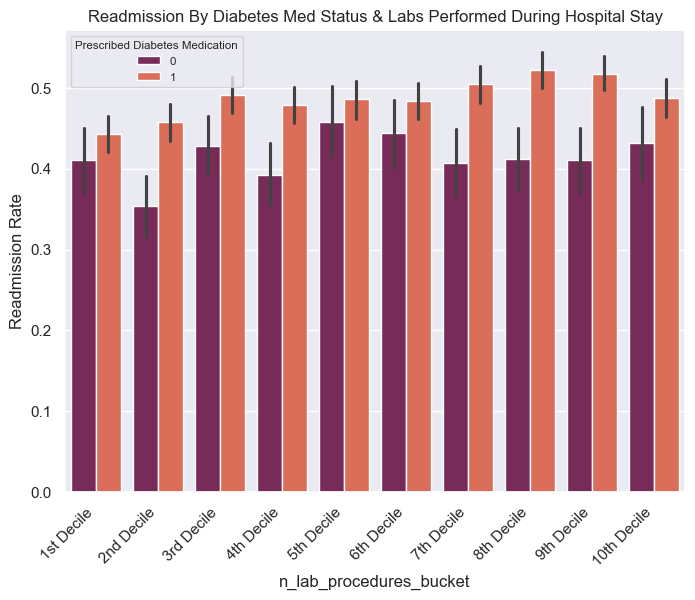

C:\Users\skyge\AppData\Local\Temp\ipykernel_21800\4095979310.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')


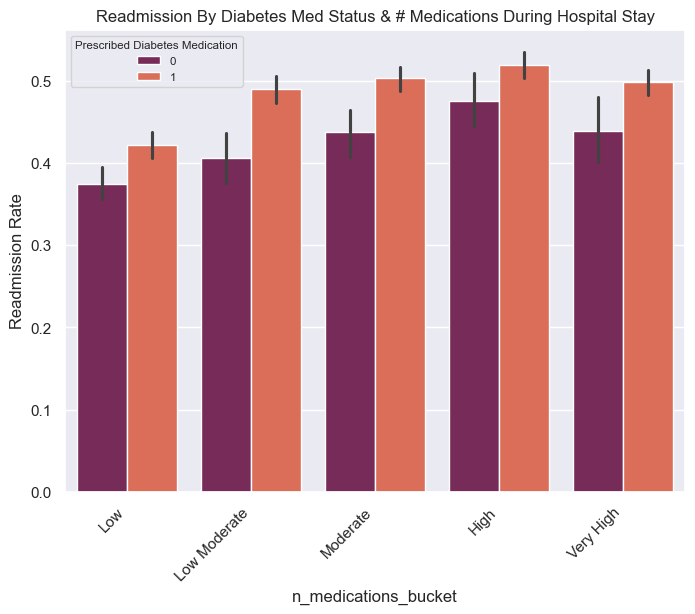

In [17]:
cols = {
        'n_inpatient_bucket':'# of Inpatient Visits Previous Year',
        "n_outpatient_bucket":'# Outpatient Visits Previous Year',
        "n_emergency_bucket":'# ER Visits Previous Year',
        "n_procedures":'Procedures During Hospital Stay',
        "n_lab_procedures_bucket":'Labs Performed During Hospital Stay',
        "n_medications_bucket":'# Medications During Hospital Stay'
        }
df_chart = df_all.sort_values('age')

for i in cols.keys():
    #df_chart.head()
    chart = sns.barplot(data=df_chart,x=i,y="readmitted",hue='diabetes_med',palette = 'rocket',errorbar=('ci', 95))
    chart.set_xticklabels(chart.get_xticklabels(), rotation=45, horizontalalignment='right')
    #chart.set(ylim=(0.3, 1.2))
    sns.set(rc={'figure.figsize':(8,6)})
    plt.legend(loc='upper left',title='Prescribed Diabetes Medication',fontsize='x-small',title_fontsize='x-small')
    plt.ylabel('Readmission Rate')
    plt.title("Readmission By Diabetes Med Status & "+cols[i])
    plt.show()

In [18]:
from scipy.stats import ttest_ind

for i in df_all['age'].sort_values().unique(): #Age groupings
    #define samples
    nonDiabetics = df_all[(df_all['Diabetes_ind']==0) & (df_all['age'] == i)]
    diabetics = df_all[(df_all['Diabetes_ind']==1) & (df_all['age'] == i)]

    print('T-test results in group: ',i)
    #perform independent two sample t-test
    print('Non-Diabetics Avg Readmittance: ',"{:.2f}%".format(np.mean(nonDiabetics['readmitted'])*100))
    print('Diabetics Avg Readmittance: ',"{:.2f}%".format(np.mean(diabetics['readmitted'])*100))
    print("T-Statistic {:.2f}:".format(ttest_ind(nonDiabetics['readmitted'], diabetics['readmitted']).statistic))
    print("P-Value {:.2f}%:".format(ttest_ind(nonDiabetics['readmitted'], diabetics['readmitted']).pvalue*100))
    print('')

T-test results in group:  (40-50)
Non-Diabetics Avg Readmittance:  43.53%
Diabetics Avg Readmittance:  45.40%
T-Statistic -0.94:
P-Value 34.52%:

T-test results in group:  (50-60)
Non-Diabetics Avg Readmittance:  44.58%
Diabetics Avg Readmittance:  43.62%
T-Statistic 0.64:
P-Value 52.30%:

T-test results in group:  (60-70)
Non-Diabetics Avg Readmittance:  47.69%
Diabetics Avg Readmittance:  45.31%
T-Statistic 1.75:
P-Value 7.97%:

T-test results in group:  (70-80)
Non-Diabetics Avg Readmittance:  49.00%
Diabetics Avg Readmittance:  48.33%
T-Statistic 0.52:
P-Value 60.54%:

T-test results in group:  (80-90)
Non-Diabetics Avg Readmittance:  48.70%
Diabetics Avg Readmittance:  52.20%
T-Statistic -2.04:
P-Value 4.10%:

T-test results in group:  (90-100)
Non-Diabetics Avg Readmittance:  41.73%
Diabetics Avg Readmittance:  43.41%
T-Statistic -0.40:
P-Value 68.98%:



In [19]:
for i in df_all['age'].sort_values().unique(): #Age groupings
    #define samples
    noMeds = df_all[(df_all['diabetes_med']==0) & (df_all['age'] == i)]
    meds = df_all[(df_all['diabetes_med']==1) & (df_all['age'] == i)]

    print('T-test results in group: ',i)
    #perform independent two sample t-test
    print('No Diabetes Meds: ',"{:.2f}%".format(np.mean(noMeds['readmitted'])*100))
    print('Yes Diabetes Meds: ',"{:.2f}%".format(np.mean(meds['readmitted'])*100))
    print("T-Statistic {:.2f}:".format(ttest_ind(noMeds['readmitted'], meds['readmitted']).statistic))
    print("P-Value {:.2f}%:".format(ttest_ind(noMeds['readmitted'], meds['readmitted']).pvalue*100))
    print('')

T-test results in group:  (40-50)
No Diabetes Meds:  38.59%
Yes Diabetes Meds:  46.33%
T-Statistic -3.33:
P-Value 0.09%:

T-test results in group:  (50-60)
No Diabetes Meds:  40.19%
Yes Diabetes Meds:  45.25%
T-Statistic -2.80:
P-Value 0.52%:

T-test results in group:  (60-70)
No Diabetes Meds:  41.84%
Yes Diabetes Meds:  48.23%
T-Statistic -4.06:
P-Value 0.00%:

T-test results in group:  (70-80)
No Diabetes Meds:  42.31%
Yes Diabetes Meds:  50.77%
T-Statistic -5.94:
P-Value 0.00%:

T-test results in group:  (80-90)
No Diabetes Meds:  42.67%
Yes Diabetes Meds:  51.85%
T-Statistic -5.35:
P-Value 0.00%:

T-test results in group:  (90-100)
No Diabetes Meds:  37.44%
Yes Diabetes Meds:  44.07%
T-Statistic -1.67:
P-Value 9.50%:



## Tiền xử lý Dữ liệu

> **Lưu ý chống rò rỉ dữ liệu (data leakage)**
> - Cột mục tiêu `readmitted` **không được** đưa vào bất kỳ bước biến đổi nào của X (scaler, PCA, log…).
> - Chia train/test **trước**, mọi bước biến đổi chỉ `fit` trên tập train → đặt trong `Pipeline`.
> - Phiên bản cũ của notebook chạy PCA trên cả bảng (có cả `readmitted`) nên cho kết quả ảo 86–99%. Đã loại bỏ.
> - PCA cũng bị bỏ: dữ liệu chỉ có vài chục cột, mô hình cây không cần PCA, và PCA làm mất khả năng giải thích.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Nhóm đặc trưng
num_cols = ['time_in_hospital', 'n_lab_procedures', 'n_procedures',
            'n_medications', 'n_outpatient', 'n_inpatient', 'n_emergency']
bin_cols = ['change', 'diabetes_med', 'Diabetes_ind',
            'glucose_test_ind', 'A1Ctest_ind', 'age_t']
cat_cols = ['medical_specialty', 'diag_1', 'diag_2', 'diag_3']

X = df_all[num_cols + bin_cols + cat_cols]   # KHÔNG chứa 'readmitted'
y = df_all['readmitted']
assert 'readmitted' not in X.columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.275, random_state=123, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (18124, 17) | X_test: (6876, 17)


## Tiền xử lý bằng Pipeline (chỉ học từ tập train)

In [21]:
prep = ColumnTransformer([
    ('num', make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
], remainder='passthrough')   # bin_cols giữ nguyên

models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=10,
                                           min_samples_leaf=5, random_state=123, n_jobs=-1),
    # 'HistGradientBoosting': HistGradientBoostingClassifier(random_state=123),
    'KNN': KNeighborsClassifier(n_neighbors=20),
}

## So sánh mô hình bằng Cross-Validation (trên tập train)

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
rows = []
for name, m in models.items():
    pipe = Pipeline([('prep', prep), ('model', m)])
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=['accuracy', 'f1', 'roc_auc'])
    rows.append({'model': name,
                 'accuracy': res['test_accuracy'].mean(),
                 'f1': res['test_f1'].mean(),
                 'roc_auc': res['test_roc_auc'].mean(),
                 'auc_std': res['test_roc_auc'].std()})

df_cv = pd.DataFrame(rows).set_index('model').sort_values('roc_auc', ascending=False)
display(df_cv.round(4))

,accuracy,f1,roc_auc,auc_std
model,,,,
RandomForest,0.6192,0.5382,0.6623,0.0059
LogisticRegression,0.6138,0.5257,0.6513,0.0045
KNN,0.6027,0.5161,0.6327,0.0111


## Đánh giá trên tập test (chỉ chạm tập test một lần)

In [23]:
best_name = df_cv.index[0]
print("Mô hình tốt nhất theo CV ROC-AUC:", best_name)

best = Pipeline([('prep', prep), ('model', models[best_name])]).fit(X_train, y_train)
y_pred = best.predict(X_test)
y_proba = best.predict_proba(X_test)[:, 1]

print("Train accuracy:", "{:.2f}%".format(best.score(X_train, y_train)*100))
print("Test accuracy :", "{:.2f}%".format(accuracy_score(y_test, y_pred)*100))
print("ROC-AUC       :", "{:.4f}".format(roc_auc_score(y_test, y_proba)))
print()
print(classification_report(y_test, y_pred, target_names=['Không tái nhập viện', 'Tái nhập viện']))

Mô hình tốt nhất theo CV ROC-AUC: RandomForest
Train accuracy: 66.89%
Test accuracy : 61.42%
ROC-AUC       : 0.6433

                     precision    recall  f1-score   support

Không tái nhập viện       0.61      0.75      0.67      3643
      Tái nhập viện       0.62      0.47      0.53      3233

           accuracy                           0.61      6876
          macro avg       0.62      0.61      0.60      6876
       weighted avg       0.62      0.61      0.61      6876



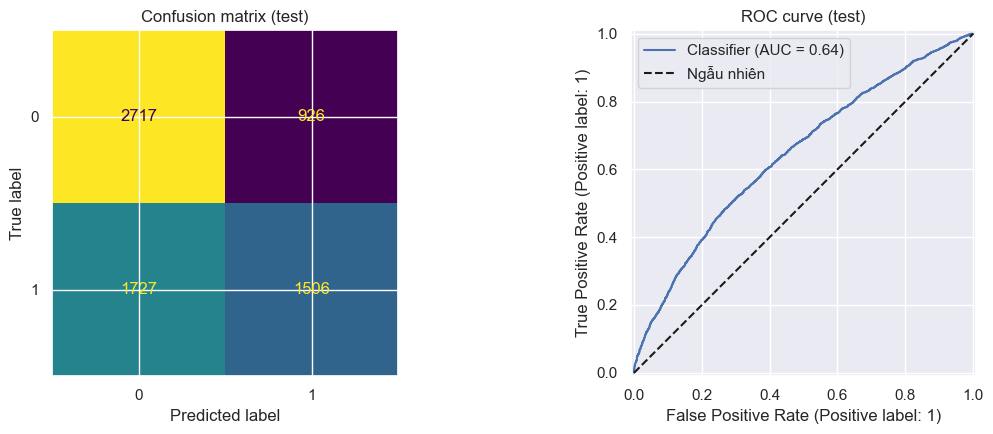

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1])
ax[1].plot([0, 1], [0, 1], 'k--', label='Ngẫu nhiên')
ax[1].set_title("ROC curve (test)")
ax[1].legend()
plt.tight_layout()
plt.show()

## Mức độ quan trọng của đặc trưng (Permutation Importance)

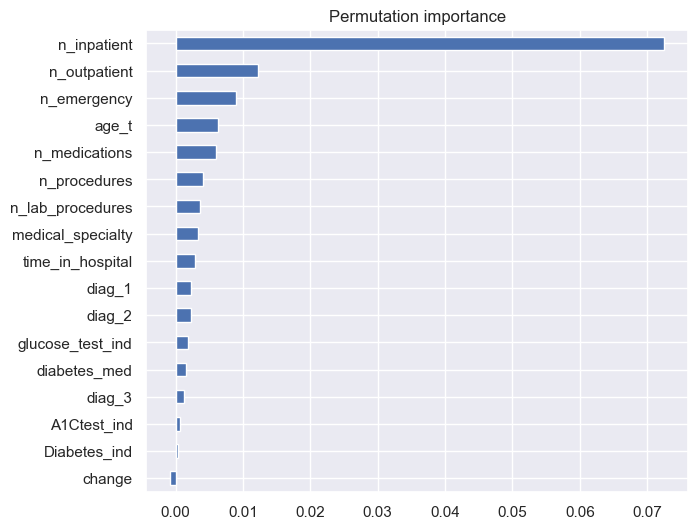

In [25]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best, X_test, y_test, scoring='roc_auc',
                              n_repeats=10, random_state=123, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind='barh', figsize=(7, 6))
plt.title("Permutation importance")
plt.show()

## Tinh chỉnh siêu tham số (RandomizedSearchCV trên tập train)

In [26]:
from scipy.stats import randint, loguniform

pipe_hgb = Pipeline([('prep', prep),
                     ('model', HistGradientBoostingClassifier(random_state=123))])

param_dist = {
    'model__learning_rate': loguniform(0.01, 0.3),
    'model__max_depth': randint(2, 8),
    'model__max_leaf_nodes': randint(8, 40),
    'model__min_samples_leaf': randint(20, 200),
    'model__l2_regularization': loguniform(1e-3, 10),
}

search = RandomizedSearchCV(pipe_hgb, param_dist, n_iter=25, cv=cv,
                            scoring='roc_auc', random_state=123, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV ROC-AUC: {:.4f}".format(search.best_score_))

tuned_proba = search.predict_proba(X_test)[:, 1]
print("Test accuracy: {:.2f}%".format(accuracy_score(y_test, search.predict(X_test))*100))
print("Test ROC-AUC : {:.4f}".format(roc_auc_score(y_test, tuned_proba)))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best params: {'model__l2_regularization': np.float64(5.017991929015982), 'model__learning_rate': np.float64(0.175084879616663), 'model__max_depth': 6, 'model__max_leaf_nodes': 9, 'model__min_samples_leaf': 136}
Best CV ROC-AUC: 0.6637
Test accuracy: 60.97%
Test ROC-AUC : 0.6449


## Kiểm thử với LazyPredict (đã sửa: dùng dữ liệu đã tiền xử lý đúng cách)

In [27]:
# !pip install lazypredict
from lazypredict.Supervised import LazyClassifier
from sklearn.metrics import cohen_kappa_score

# fit trên train, chỉ transform trên test
Xtr = prep.fit_transform(X_train)
Xte = prep.transform(X_test)
Xtr = Xtr.toarray() if hasattr(Xtr, 'toarray') else Xtr
Xte = Xte.toarray() if hasattr(Xte, 'toarray') else Xte

lazy = LazyClassifier(verbose=0, ignore_warnings=True,
                      custom_metric=cohen_kappa_score,
                      predictions=False, random_state=42, classifiers="all")
models_class, _ = lazy.fit(Xtr, Xte, y_train, y_test)
models_class.sort_values(by='ROC AUC', ascending=False).head(10)

c:\Users\skyge\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,cohen_kappa_score,Time Taken
Model,,,,,,,,
LGBMClassifier,0.610675,0.604751,0.643788,0.606606,0.609653,0.610675,0.211420,0.174815
SVC,0.611547,0.603817,0.641014,0.604533,0.611660,0.611547,0.210302,23.648793
LogisticRegression,0.606166,0.596946,0.633091,0.596015,0.607403,0.606166,0.196971,0.063586
CalibratedClassifierCV,0.606457,0.597116,0.633003,0.596036,0.607873,0.606457,0.197365,0.311342
LinearSVC,0.606312,0.596735,0.632997,0.595342,0.608020,0.606312,0.196685,0.140866
LinearDiscriminantAnalysis,0.606603,0.597027,0.632965,0.595641,0.608341,0.606603,0.197278,0.080984
RidgeClassifier,0.606603,0.597027,0.632965,0.595641,0.608341,0.606603,0.197278,0.054772
RidgeClassifierCV,0.606603,0.597027,0.632965,0.595641,0.608341,0.606603,0.197278,0.066830
AdaBoostClassifier,0.606894,0.598624,0.630102,0.598781,0.607167,0.606894,0.199995,0.661077


## Kết luận
- Bộ dữ liệu này khó dự đoán: accuracy thực tế khoảng 60–66%, ROC-AUC khoảng 0.63–0.68.
- Các đặc trưng liên quan nhất tới tái nhập viện: lịch sử nhập viện nội trú (`n_inpatient`), cấp cứu, thuốc tiểu đường (`diabetes_med`) và thay đổi thuốc (`change`).

In [28]:
import joblib, json, sklearn

final_model = search.best_estimator_
joblib.dump(final_model, 'readmission_model.joblib')
meta = {
    'feature_columns': list(X.columns),
    'sklearn_version': sklearn.__version__,
    'test_roc_auc': float(roc_auc_score(y_test, final_model.predict_proba(X_test)[:, 1])),
}
json.dump(meta, open('model_meta.json', 'w'), ensure_ascii=False, indent=2)